# ICS503 · Data Engineering and Visualization · Milestone 1
### Affordable housing project starts × serious road-injury reporting in New York City (2022–2025)

**GIU · Winter 2026 · Due 9 November 2026**

**Core question:** At the borough × year level, do locations with more affordable units in housing projects that **started** also have more records and severe injuries reported in NYC DOT's **Serious Injury Response, Tracking & Analysis Program (SIRTA)**?

**Why it matters:** Housing and transportation investments interact spatially; exploratory co-occurrence can identify places warranting closer safety reviews. It cannot establish causation or individual-level risk.

**Sources:** [H2: HPD Affordable Housing Production by Building](https://data.cityofnewyork.us/d/hg8x-zxpr) and [T4: DOT SIRTA](https://data.cityofnewyork.us/d/xeqp-qz8h). Both are recommended in the supplied catalog; there is **exactly one source dataset per domain**, and each has at least nine columns.

**Important:** Execute this notebook in the same folder as `pipeline.py` and `app.py`. In Google Colab upload both `.py` files into the same working directory first. The first run downloads real observations over the internet. No findings in this notebook are precomputed or fabricated.


## 1. Imports, reproducibility, and live source provenance

The source datasets are relatively small (about 9.6K and 13.8K rows at the time of source verification), so the public Socrata API with an explicit `$limit=50000` permits a complete download as long as row counts remain below that ceiling. If an API response reaches 50K, the ETL fails with an actionable error rather than quietly analyzing a truncated file. Source CSVs are cached for reproducibility.


In [1]:
import os, json, warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
from IPython.display import display, Markdown
from pipeline import (DATA, HOUSING_ID, TRANSPORT_ID, START_YEAR, END_YEAR,
                      download_dataset, overview, clean_housing, clean_transport, aggregate)
print('Working directory:', os.getcwd())
print('Source URLs:', f'https://data.cityofnewyork.us/d/{HOUSING_ID}', f'https://data.cityofnewyork.us/d/{TRANSPORT_ID}')

Working directory: D:\data vs\ICS503_Project\ICS503_NYC_Milestone1
Source URLs: https://data.cityofnewyork.us/d/hg8x-zxpr https://data.cityofnewyork.us/d/xeqp-qz8h


In [2]:
raw_housing = download_dataset(HOUSING_ID, DATA/'housing_raw.csv')
raw_transport = download_dataset(TRANSPORT_ID, DATA/'transport_raw.csv')
assert raw_housing.shape[1] >= 9 and raw_transport.shape[1] >= 9
print('Housing shape:', raw_housing.shape, '| SIRTA shape:', raw_transport.shape)
display(raw_housing.head(3), raw_transport.head(3))

Housing shape: (9551, 41) | SIRTA shape: (13754, 23)


,project_id,project_name,project_start_date,project_completion_date,building_id,house_number,street_name,borough,postcode,bbl,...,_2_br_units,_3_br_units,_4_br_units,_5_br_units,_6_br_units,unknown_br_units,counted_rental_units,counted_homeownership_units,all_counted_units,total_units
0,68872,177-06 WEXFORD TERRACE,2026-06-30T00:00:00.000,NaN,991637.0,177-06,WEXFORD TERRACE,Queens,11432.0,4.098350e+09,...,NaN,NaN,NaN,NaN,NaN,NaN,9.0,NaN,9.0,43
1,72436,ST. NICK'S. 819 GRAND STREET,2026-06-30T00:00:00.000,NaN,1021347.0,819,GRAND STREET,Brooklyn,11211.0,3.029220e+09,...,NaN,NaN,NaN,NaN,NaN,NaN,187.0,NaN,187.0,187
2,72449,BREMOND KING DAVIS.YR15.FY26,2026-06-30T00:00:00.000,NaN,21199.0,127,EDGECOMBE AVENUE,Manhattan,10030.0,1.020480e+09,...,20.0,NaN,NaN,NaN,NaN,NaN,25.0,NaN,25.0,25


,open_data_crash_id,crash_date,crash_time,crash_police_precinct,crash_borough,total_non_severe_injuries,total_severe_injuries,total_fatalities,latitude,longitude,...,highway_reference_marker,zipcode,similar_fatalities_severe,similar_fatalities_all,community_board,council_district,bin,bbl,census_tract_2020_,neighborhood_tabulation_area_nta_2020_
0,4492364.0,2022-01-01T00:00:00.000,01:28,46.0,Bronx,1.0,1.0,0.0,40.858707,-73.90370,...,NaN,NaN,0.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN
1,4491159.0,2022-01-01T00:00:00.000,04:33,46.0,Bronx,0.0,1.0,0.0,NaN,NaN,...,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
2,4491487.0,2022-01-01T00:00:00.000,05:55,47.0,Bronx,0.0,1.0,0.0,40.871550,-73.86428,...,NaN,NaN,0.0,0.0,212.0,12.0,2056281.0,2.045980e+09,372.0,BX1201


## 2. Dataset overview & descriptive EDA (before cleaning)

**H2 grain:** A building may be represented in more than one housing project, so removing duplicates by building ID alone would delete legitimate building-project occurrences. Variables: borough, project ID, building ID, project start date, completion date (often absent), affordable counted units, construction type, coordinates and postal code.

**T4 grain:** A SIRTA record documents a serious-road-crash case reviewed/reported by this specific program, not every recorded collision in NYC. Variables: crash date, crash borough, severe injuries, fatalities, streets, location, and other injury/administrative fields.

In particular, **project start** and **project completion** are not equivalent. We use *project_start_date* because it is more consistently available and label the metric correctly in all outputs.


In [3]:
display(pd.DataFrame([overview(raw_housing,'HPD Building'), overview(raw_transport,'DOT SIRTA')]).drop(columns=['null_percentage_top_10']))
print('Housing missingness (%), top 12:')
display((raw_housing.isna().mean().sort_values(ascending=False).head(12)*100).round(1).to_frame('Missing %'))
print('SIRTA missingness (%), top 12:')
display((raw_transport.isna().mean().sort_values(ascending=False).head(12)*100).round(1).to_frame('Missing %'))
print('Housing numerical summary:')
display(raw_housing.describe(include='number').T.head(12))
print('SIRTA numerical summary:')
display(raw_transport.describe(include='number').T.head(12))

,dataset,rows,columns,duplicate_full_rows
0,HPD Building,9551,41,0
1,DOT SIRTA,13754,23,3


Housing missingness (%), top 12:


,Missing %
_6_br_units,99.7
_5_br_units,99.2
_4_br_units,94.1
unknown_br_units,92.8
other_income_units,85.8
moderate_income_units,82.3
extremely_low_income_units,78.2
middle_income_units,71.8
counted_homeownership_units,71.4
studio_units,66.5


SIRTA missingness (%), top 12:


,Missing %
highway_reference_marker,92.4
address,81.3
bin,79.7
bbl,79.7
census_tract_2020_,71.9
neighborhood_tabulation_area_nta_2020_,71.9
council_district,71.9
community_board,71.9
zipcode,41.3
cross_street,41.0


Housing numerical summary:


,count,mean,std,min,25%,50%,75%,max
project_id,9551.0,6.712525e+04,8.463040e+03,4.421800e+04,6.141850e+04,6.878100e+04,7.385050e+04,8.224900e+04
building_id,7602.0,5.827297e+05,4.010576e+05,3.750000e+02,1.179762e+05,8.056255e+05,9.806888e+05,1.022537e+06
postcode,7593.0,1.078041e+04,5.044376e+02,1.000100e+04,1.045300e+04,1.110200e+04,1.122100e+04,1.169400e+04
bbl,7530.0,2.510122e+09,9.720933e+08,1.000050e+09,2.026850e+09,3.008498e+09,3.039568e+09,5.080478e+09
bin,7530.0,2.643422e+06,1.061980e+06,1.000000e+06,2.006548e+06,3.005974e+06,3.418164e+06,5.174441e+06
council_district,9551.0,2.594189e+01,1.409208e+01,1.000000e+00,1.300000e+01,2.700000e+01,3.800000e+01,5.100000e+01
census_tract,7593.0,1.131351e+04,2.580537e+04,1.000000e+00,2.150000e+02,3.860000e+02,2.001000e+03,1.227040e+05
latitude,7593.0,4.074793e+01,8.319109e-02,4.050991e+01,4.067703e+01,4.073165e+01,4.082634e+01,4.090663e+01
longitude,7593.0,-7.391975e+01,5.656077e-02,-7.424769e+01,-7.394968e+01,-7.392364e+01,-7.389076e+01,-7.373062e+01
latitude_internal,7507.0,4.074830e+01,8.311325e-02,4.051005e+01,4.067726e+01,4.073172e+01,4.082652e+01,4.090688e+01


SIRTA numerical summary:


,count,mean,std,min,25%,50%,75%,max
open_data_crash_id,13310.0,7.271533e+06,1.128930e+07,2.126022e+06,4.612503e+06,4.718838e+06,4.814223e+06,1.213261e+08
crash_police_precinct,13310.0,6.783787e+01,3.468395e+01,1.000000e+00,4.200000e+01,6.800000e+01,1.040000e+02,1.230000e+02
total_non_severe_injuries,13310.0,2.704733e-01,8.360310e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.900000e+01
total_severe_injuries,13310.0,1.011495e+00,4.515143e-01,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,7.000000e+00
total_fatalities,13310.0,8.279489e-02,2.943044e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,5.000000e+00
latitude,10868.0,4.073064e+01,8.337807e-02,4.049967e+01,4.066785e+01,4.072671e+01,4.080066e+01,4.091247e+01
longitude,10868.0,-7.392154e+01,8.192903e-02,-7.424857e+01,-7.396879e+01,-7.392369e+01,-7.387474e+01,-7.370060e+01
zipcode,8072.0,1.081959e+04,5.437498e+02,1.000000e+04,1.031200e+04,1.120400e+04,1.123500e+04,1.169400e+04
similar_fatalities_severe,11917.0,9.549383e-02,4.217294e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,9.000000e+00
similar_fatalities_all,13310.0,1.544328e+00,5.857394e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,2.960000e+02


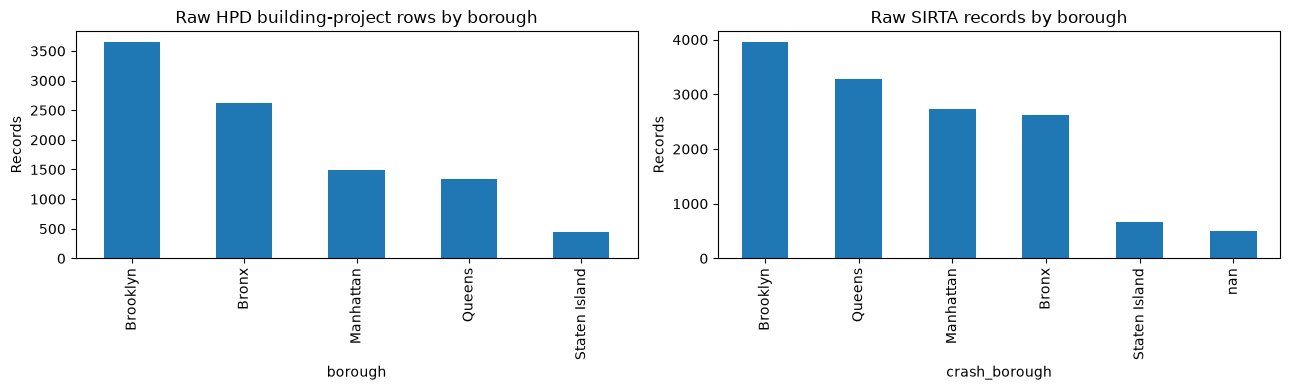

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13,4))
raw_housing['borough'].value_counts(dropna=False).plot(kind='bar', ax=axes[0], title='Raw HPD building-project rows by borough')
raw_transport['crash_borough'].value_counts(dropna=False).plot(kind='bar', ax=axes[1], title='Raw SIRTA records by borough')
axes[0].set_ylabel('Records'); axes[1].set_ylabel('Records')
plt.tight_layout(); plt.show()

## 3. Pre-integration cleaning and validation

**Actions:**

- Drop exact duplicate full rows, not legitimate repeated buildings across *different* housing projects.
- Normalize borough names and parse dates with coercion; restrict to **complete years 2022–2025** to avoid partial 2026 bias.
- Convert injury and housing-unit fields to numbers. Exclude missing/negative primary counts rather than invent values. Housing project-unit nulls cannot reliably be interpreted as zero. Missing injury severity/fatality counts are not silently made zero; such records are excluded. A missing *non-severe injury* count is set to zero **only for an ancillary metric**, which is not used in the required main analyses.
- Detect housing unit high-end IQR outliers. We **flag but keep them**: a large residential development need not be an error. Negative numeric counts are rejected as logically impossible.
- Standardize construction categories. Keep project start semantics and explain missing completion dates, if present.

This is a transparent data-quality policy; changing these rules would require rechecking observed data.


In [5]:
housing, housing_audit = clean_housing(raw_housing)
transport, transport_audit = clean_transport(raw_transport)
print('Housing cleaning audit:'); display(pd.Series(housing_audit))
print('Transportation cleaning audit:'); display(pd.Series(transport_audit))
print('Post-cleaning shapes:', housing.shape,transport.shape)
assert housing['year'].between(2022,2025).all()
assert transport['year'].between(2022,2025).all()
assert (housing['all_counted_units']>=0).all()
assert (transport['total_severe_injuries']>=0).all()

Housing cleaning audit:


input                                                                           9551
exact_duplicates_removed                                                           0
iqr_flagged_units_not_deleted                                                   1249
invalid_or_out_of_scope_removed                                                 6289
output                                                                          3262
granularity                        building-project record (repeated buildings ac...
dtype: object

Transportation cleaning audit:


input                                                                          13754
exact_duplicates_removed                                                           3
invalid_or_out_of_scope_removed                                                 1829
output                                                                         11922
granularity                        SIRTA record; NOT all NYC crashes, and not pop...
dtype: object

Post-cleaning shapes: (3262, 43) (11922, 26)


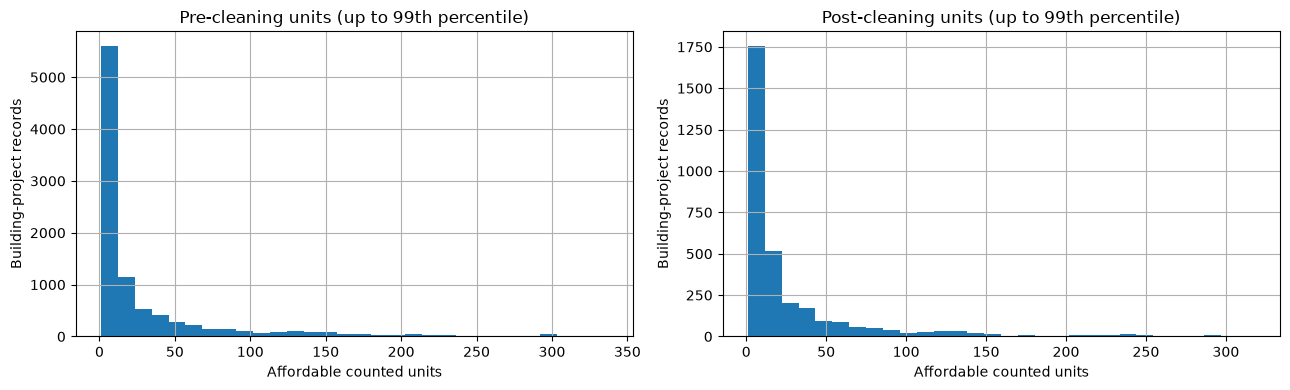

In [6]:
fig,ax=plt.subplots(1,2,figsize=(13,4))
raw_numeric=pd.to_numeric(raw_housing['all_counted_units'],errors='coerce')
raw_numeric[(raw_numeric>=0)&(raw_numeric<=raw_numeric.quantile(.99))].hist(bins=30,ax=ax[0]);ax[0].set_title('Pre-cleaning units (up to 99th percentile)')
housing['all_counted_units'][housing['all_counted_units']<=housing['all_counted_units'].quantile(.99)].hist(bins=30,ax=ax[1]);ax[1].set_title('Post-cleaning units (up to 99th percentile)')
for a in ax: a.set_xlabel('Affordable counted units');a.set_ylabel('Building-project records')
plt.tight_layout();plt.show()

## 4. Integration: aggregate independently, never join individual rows

There is **no natural record-to-record foreign key** between these domains. Joining directly on borough would multiply housing rows by injury rows and create false totals. Instead:

1. Aggregate housing to `(borough, year)` → affordable units, building-project records, distinct housing projects, and construction/preservation units.
2. Aggregate SIRTA to `(borough, year)` → SIRTA records, severe injuries, deaths, non-severe injuries.
3. Outer-join the aggregates **only for coverage auditing**, then analyze common borough-year combinations via a validated one-to-one merge.
4. Do not fill newly unmatched groups with zero. Unmatched source observations mean no valid joint comparison. Convert metrics to numeric and verify key uniqueness after the join.

The level is coarse enough to be shared by both sources, and finer ZIP/block/time joins may be sparse or mismatched. This is a **geographical-temporal co-occurrence** study, not a study of crashes close to specific projects.


In [7]:
integrated, integration_audit = aggregate(housing,transport)
print('Post-integration audit:');display(pd.Series(integration_audit))
print('First rows:');display(integrated.head(10))
assert integrated[['borough','year']].duplicated().sum()==0
assert integrated[['housing_units','sirta_records','severe_injuries']].notna().all().all()
print('Numeric summary:');display(integrated.describe().T)

Post-integration audit:


housing_borough_year_groups         20
transport_borough_year_groups       20
matched                             20
housing_only                         0
transport_only                       0
integrated_rows_after_post_clean    20
key_duplicates_after_join            0
dtype: int64

First rows:


,borough,year,housing_units,housing_records,housing_projects,new_units,preservation_units,sirta_records,severe_injuries,fatalities,nonsevere_injuries
0,Bronx,2022,5191.0,181,150,2843.0,2348.0,600,600.0,55.0,141.0
1,Bronx,2023,9335.0,263,226,5631.0,3704.0,600,600.0,46.0,189.0
2,Bronx,2024,9800.0,331,186,5915.0,3885.0,622,638.0,52.0,194.0
3,Bronx,2025,8163.0,259,198,4507.0,3656.0,543,559.0,33.0,158.0
4,Brooklyn,2022,6450.0,266,225,5362.0,1088.0,885,866.0,76.0,228.0
5,Brooklyn,2023,10777.0,363,237,5109.0,5668.0,874,871.0,66.0,232.0
6,Brooklyn,2024,8987.0,261,200,5201.0,3786.0,919,916.0,65.0,281.0
7,Brooklyn,2025,8350.0,265,201,5005.0,3345.0,879,895.0,76.0,220.0
8,Manhattan,2022,3163.0,68,48,1426.0,1737.0,570,575.0,40.0,114.0
9,Manhattan,2023,5403.0,97,56,1154.0,4249.0,653,654.0,39.0,174.0


Numeric summary:


,count,mean,std,min,25%,50%,75%,max
year,20.0,2023.50,1.147079,2022.0,2022.75,2023.5,2024.25,2025.0
housing_units,20.0,5195.60,3327.861371,33.0,3060.25,5217.0,8209.75,10777.0
housing_records,20.0,163.10,103.220714,21.0,96.50,126.5,261.50,363.0
housing_projects,20.0,120.40,76.721918,21.0,54.00,112.5,198.50,237.0
new_units,20.0,2717.15,2118.146938,23.0,1132.00,2422.0,5031.00,5915.0
preservation_units,20.0,2478.45,1727.704241,8.0,979.50,2497.0,3804.25,5668.0
sirta_records,20.0,596.10,258.165165,133.0,563.25,630.5,775.50,919.0
severe_injuries,20.0,600.55,258.428749,123.0,571.00,634.0,813.75,916.0
fatalities,20.0,48.50,23.084513,11.0,37.50,49.0,67.25,85.0
nonsevere_injuries,20.0,161.40,72.935732,43.0,111.75,181.5,221.25,281.0


In [8]:
from pipeline import run

# Generate cleaned datasets and quality report
housing, transport, integrated, quality_report = run()

display(pd.DataFrame({
    'Name': ['Housing raw', 'SIRTA raw', 'Matched borough-years'],
    'Rows': [len(raw_housing), len(raw_transport), len(integrated)]
}))

print('Files written:')
for csv_path in sorted(DATA.glob('*.csv')):
    print(csv_path)

SUCCESS: downloaded official NYC data, cleaned, joined, and exported CSVs
{
  "housing_rows": 3262,
  "transport_rows": 11922,
  "housing_borough_year_groups": 20,
  "transport_borough_year_groups": 20,
  "matched": 20,
  "housing_only": 0,
  "transport_only": 0,
  "integrated_rows_after_post_clean": 20,
  "key_duplicates_after_join": 0
}


,Name,Rows
0,Housing raw,9551
1,SIRTA raw,13754
2,Matched borough-years,20


Files written:
D:\data vs\ICS503_Project\ICS503_NYC_Milestone1\data\housing_clean.csv
D:\data vs\ICS503_Project\ICS503_NYC_Milestone1\data\housing_raw.csv
D:\data vs\ICS503_Project\ICS503_NYC_Milestone1\data\integrated.csv
D:\data vs\ICS503_Project\ICS503_NYC_Milestone1\data\transport_clean.csv
D:\data vs\ICS503_Project\ICS503_NYC_Milestone1\data\transport_raw.csv


## 5. Validation visualizations (and initial discovery)

These EDA charts are not the final 12 research-question charts. They verify group coverage and show the distribution of both source domains after cleaning and integration.


In [9]:
display(px.bar(integrated,x='year',y='housing_units',color='borough',barmode='group',
              title='Affordable units associated with project starts by borough/year'))
display(px.bar(integrated,x='year',y='severe_injuries',color='borough',barmode='group',
              title='SIRTA severe injuries by borough/year'))
display(px.scatter(integrated,x='housing_units',y='sirta_records',color='borough',hover_data=['year'],
                  title='Cross-domain validation: housing starts versus SIRTA records'))

## 6. Research questions & one chart per question

Each question below is investigated with a relationship-relevant interactive Plotly figure in the website. **Do not make causal claims.** Questions 1–8 satisfy the minimum four-member team requirement. Questions 9–10 add a fifth member; questions 11–12 add a sixth. Each member should confirm that their assigned work was actually done by them before attribution.

| Chart | Research question | Core visual |
|---|---|---|
| 1 | Do more housing-unit starts correspond with more SIRTA records? | Borough-year scatter |
| 2 | Do housing-unit starts correspond with more severe injuries? | Borough-year scatter |
| 3 | How do new-construction units compare with reported fatalities? | Scatter |
| 4 | How do preservation units compare with SIRTA record activity? | Scatter |
| 5 | Are more housing projects associated with more severe injuries? | Scatter |
| 6 | Are more building-project records associated with reported fatalities? | Scatter |
| 7 | Which areas have both substantial housing starts and severe-injury activity? | Cross-domain bubble scatter |
| 8 | Are the relative trends of housing starts and severe injuries synchronized? | Indexed time series |
| 9 | Which borough-years are relatively above or below peers in housing versus injuries? | Difference-of-z-scores heatmap |
| 10 | How do borough shares of housing and SIRTA differ? | Paired percentage-of-total bars |
| 11 | Do annual changes in starts and SIRTA records move together? | Growth-rate line |
| 12 | Does mean project size correspond with severe injuries per SIRTA record? | Scatter |

The charts tell a **descriptive**, not predictive, story. Z-score comparisons describe relative intensity, **not road-safety risk**, and the numerator/denominator in Chart 12 are intensities within two separate datasets.


In [10]:
from app import figures, CHART_QUESTIONS
all_figures = figures(integrated)
assert len(all_figures)==12
# Display all 12 exactly as the website will (interactive hover/zoom).
for i,fig in enumerate(all_figures, start=1):
    print(f'Visualization {i} — {CHART_QUESTIONS[i-1]}')
    display(fig)

Visualization 1 — Q1 · Do borough-years with more affordable units started also have more SIRTA records?


Visualization 2 — Q2 · How do housing starts relate to severe traffic injuries by borough-year?


Visualization 3 — Q3 · Are new-construction housing units associated with more road fatalities?


Visualization 4 — Q4 · Does housing preservation occur alongside higher serious-crash reporting?


Visualization 5 — Q5 · Do borough-years with more distinct housing projects also report more severe injuries?


Visualization 6 — Q6 · How does building-level project activity align with road fatalities?


... (2 outputs left out)

Visualization 9 — Q9 · Where do housing starts and severe injuries diverge most in relative intensity?


Visualization 10 — Q10 · Which boroughs carry different shares of housing production and SIRTA records?


Visualization 11 — Q11 · Do year-on-year changes in housing starts match changes in SIRTA records?


Visualization 12 — Q12 · Do larger housing projects coincide with more severe injuries per SIRTA record?


## 7. Findings derived from the **executed dataset**, never inserted ahead of time

The outputs below will only appear after the official API has been read. The automatic summary reports descriptive counts and rankings. A high correlation would not be evidence that affordable housing causes more serious road injuries (or vice versa).


In [11]:
print('Analyzed years:', sorted(integrated.year.unique()))
print('Matched borough-year groups:', len(integrated))
print('Total units in started projects:', f'{integrated.housing_units.sum():,.0f}')
print('SIRTA records:', f'{integrated.sirta_records.sum():,.0f}')
print('SIRTA severe injuries:', f'{integrated.severe_injuries.sum():,.0f}')
print('Severe injuries per SIRTA record:', f'{integrated.severe_injuries.sum()/max(integrated.sirta_records.sum(),1):.2f}')
print('Top housing borough:', integrated.groupby('borough').housing_units.sum().idxmax())
print('Top SIRTA borough:', integrated.groupby('borough').sirta_records.sum().idxmax())
if len(integrated)>2 and integrated.housing_units.nunique()>1 and integrated.severe_injuries.nunique()>1:
    print('Exploratory Pearson r (borough-year counts, NOT causal):', round(integrated.housing_units.corr(integrated.severe_injuries),3))
else: print('Correlation undefined with insufficient independent variation.')
display(integrated.groupby('borough')[['housing_units','sirta_records','severe_injuries','fatalities']].sum().sort_values('housing_units',ascending=False))

Analyzed years: [np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
Matched borough-year groups: 20
Total units in started projects: 103,912
SIRTA records: 11,922
SIRTA severe injuries: 12,011
Severe injuries per SIRTA record: 1.01
Top housing borough: Brooklyn
Top SIRTA borough: Brooklyn
Exploratory Pearson r (borough-year counts, NOT causal): 0.686


,housing_units,sirta_records,severe_injuries,fatalities
borough,,,,
Brooklyn,34564.0,3557,3548.0,283.0
Bronx,32489.0,2365,2397.0,186.0
Manhattan,20035.0,2448,2439.0,162.0
Queens,13782.0,2974,3028.0,286.0
Staten Island,3042.0,578,599.0,53.0


## 8. Limitations, impact and alternate integration strategies

**Limitations:** Coarse borough-year aggregates can hide neighborhood disparities. Dataset coverage differs: HPD describes projects starting (or preservation activity) in a year; SIRTA only covers crashes investigated/reported within this program. Recorded totals are *not* population-adjusted crash rates or exposure-normalized risk, and citywide changes or borough size can confound comparisons. The sample has at most 5 boroughs × 4 years, so correlations are fragile. There may be variation in reporting dates and unobserved policy, road design, population and traffic changes. The project excludes non-overlapping group-year keys; no fabricated zeros were introduced.

**Alternatives:** ZIP/year joins could offer local specificity but may suffer missing or inconsistent ZIP coverage, sparse cells and ZIP borders that do not match travel patterns. Point-buffer spatial joins around project buildings require accurate coordinate coverage and careful buffers; even then, proximity does not prove causality. The catalog allows aggregation; borough/year was selected for interpretability and stable coverage.

**Impact:** NYC HPD and DOT could compare patterns and flag borough-year combinations for more geographically detailed investigation, including adjustment for traffic exposure and housing construction timing. The current graphs are for *screening*, not for allocating funds or declaring developments dangerous.

**Potential improvements:** Add neighborhood population and traffic exposure in later work (but **do not** treat those as a second housing/transport selected dataset under the milestone's exactly-one-each restriction without asking the teaching team). Compare 2023/2024 sensitivity ranges and use ZIP/year only where completeness supports them.


## 9. Website execution, QA, and group contribution record

Website source: `app.py`. Start with `python app.py` (after running this notebook), then open `http://127.0.0.1:8050`. Verify four dropdowns, typed search, central **Generate Report**, all 12 updated figures, browser hover/zoom, and story text. Deploy to Render and **test the actual public URL**. Record the deployed and GitHub URLs in your group email and README.

- **Member 1:** Questions/charts 1–2. Name/ID: **[FILL]**. Other actual contributions: **[FILL]**.
- **Member 2:** Questions/charts 3–4. Name/ID: **[FILL]**. Other actual contributions: **[FILL]**.
- **Member 3:** Questions/charts 5–6. Name/ID: **[FILL]**. Other actual contributions: **[FILL]**.
- **Member 4:** Questions/charts 7–8. Name/ID: **[FILL]**. Other actual contributions: **[FILL]**.
- **Member 5 (if applicable):** Questions/charts 9–10. Name/ID: **[FILL]**.
- **Member 6 (if applicable):** Questions/charts 11–12. Name/ID: **[FILL]**.

**Do not assert this suggested split is what happened.** Replace placeholders based on actual collaboration. All individual EDA/cleaning/integration/site/testing tasks must be truthfully documented in `TEAM_CONTRIBUTIONS.md`.


## 10. LLM prompts, dataset links, and reproducibility

**Actual project-generating request:** `i have to finish this project in one hour` with the project description and catalog PDFs provided. The generated starter code is from AI assistance. Add the **actual** additional prompting you perform in `PROMPTS_USED.md` or here, if any.

**Verification:** Source names/IDs and public schemas were checked on NYC Open Data. No real API records were downloaded or empirically analyzed in the AI assistant's local file-building environment. The charts and descriptive statistics in this notebook are calculated when **you execute the notebook on real downloaded data**. Inspect the data-quality audit and failed assertions rather than claiming an unverified project is finished.

Official source links: 

- https://data.cityofnewyork.us/d/hg8x-zxpr
- https://data.cityofnewyork.us/d/xeqp-qz8h

For submission: notebook, website code, cleaned datasets, integration/quality report, README, actual team contributions, GitHub repo URL, deployed URL, all student IDs, and group email to `ICS503Data@gmail.com`.
